First, download medical_mnist.zip from Kaggle
https://www.kaggle.com/datasets/andrewmvd/medical-mnist

import all the helper functions

In [1]:
from utils_mnist import *
import numpy as np

In [2]:
class Trainer:
    def __init__(
        self,
        args,
        train_loader,
        validation_loader,
        model,
        loss_function,
        optimizer
    ):
        """
        Store arguments, data loaders, model,
        loss function, optimizer, and device.
        """

        self.args = args
        self.train_loader = train_loader
        self.validation_loader = validation_loader

        self.loss_function = loss_function
        self.optimizer = optimizer

        # Use GPU if available
        self.device = torch.device(
            'cuda' if torch.cuda.is_available() else 'cpu'
        )

        print('Using device:', self.device)

        # Move model to CPU/GPU
        self.model = model.to(self.device)

    def overall_loop(self):
        """
        Run training for specified epochs,
        print train/validation loss each epoch.
        """

        for epoch in range(self.args['num_epochs']):

            train_losses = self.training_loop(
                self.train_loader
            )

            validation_losses = self.validation_loop(
                self.validation_loader
            )

            train_loss = np.mean(train_losses)
            validation_loss = np.mean(validation_losses)

            print(
                'Epoch [{}/{}], '
                'Train Loss: {:.4f}, '
                'Validation Loss: {:.4f}'.format(
                    epoch + 1,
                    self.args['num_epochs'],
                    train_loss,
                    validation_loss
                )
            )

    def training_loop(self, train_loader):
        """
        Iterate through training batches
        and return list of batch losses.
        """

        # Enable training mode
        self.model.train()

        losses = []

        for train_batch in train_loader:

            loss = self.training_step(train_batch)

            losses.append(loss)

        return losses

    def validation_loop(self, validation_loader):
        """
        Iterate through validation batches
        and return list of batch losses.
        """

        # Disable dropout etc.
        self.model.eval()

        losses = []

        # Validation does not need gradient
        with torch.no_grad():

            for validation_batch in validation_loader:

                loss = self.validation_step(
                    validation_batch
                )

                losses.append(loss)

        return losses

    def training_step(self, train_batch):
        """
        Forward pass
        -> compute loss
        -> backpropagation
        -> update weights
        """

        images, labels = train_batch

        # Move data to device
        images = images.to(
            self.device,
            dtype=torch.float32
        )

        labels = labels.to(
            self.device,
            dtype=torch.long
        )

        # Logistic regression requires flattened input
        if self.args['model'] == 'logistic_regression':
            images = images.reshape(
                -1,
                self.args['img_size']
            )

        # Clear previous gradients
        self.optimizer.zero_grad()

        # Forward pass
        outputs = self.model(images)

        # Compute loss
        loss = self.loss_function(
            outputs,
            labels
        )

        # Backpropagation
        loss.backward()

        # Update model weights
        self.optimizer.step()

        # Convert tensor loss to Python number
        return loss.item()

    def validation_step(self, validation_batch):
        """
        Forward pass and compute validation loss.
        No backpropagation.
        """

        images, labels = validation_batch

        images = images.to(
            self.device,
            dtype=torch.float32
        )

        labels = labels.to(
            self.device,
            dtype=torch.long
        )

        if self.args['model'] == 'logistic_regression':
            images = images.reshape(
                -1,
                self.args['img_size']
            )

        # Forward pass
        outputs = self.model(images)

        # Compute validation loss
        loss = self.loss_function(
            outputs,
            labels
        )

        return loss.item()

define all the arguments (hyperparameters)

In [3]:
# arguments
def get_arguments():
    # Hyper-parameters
    args = {'img_size': 64 * 64,
            'num_classes': 6,
            'num_epochs': 50,
            'batch_size': 16,
            'learning_rate': 0.001,
            'model': 'logistic_regression'} # MLP or logistic_regression
    return args

args = get_arguments()
print(args)

{'img_size': 4096, 'num_classes': 6, 'num_epochs': 50, 'batch_size': 16, 'learning_rate': 0.001, 'model': 'logistic_regression'}


In [4]:
# Medical MNIST dataset (images and labels)
train_loader, validation_loader = get_medical_mnist(args=args)
print('Done with data preparation')

data folder:  mmnist
categories: ['AbdomenCT', 'BreastMRI', 'CXR', 'ChestCT', 'Hand', 'HeadCT']
AbdomenCT 10000
BreastMRI 8954
CXR 10000
ChestCT 10000
Hand 10000
HeadCT 10000
length of all images: 42000
categories: ['AbdomenCT', 'BreastMRI', 'CXR', 'ChestCT', 'Hand', 'HeadCT']
AbdomenCT 10000
BreastMRI 8954
CXR 10000
ChestCT 10000
Hand 10000
HeadCT 10000
length of all images: 16954
Done with data preparation


In [6]:
print('Length of train dataset:')
print(len(train_loader.dataset))
print('Length of validation dataset:')
print(len(validation_loader.dataset))
print('Length of train dataloader:')
print(len(train_loader))
print('Length of validation dataloader:')
print(len(validation_loader))
print('Why is that?')

Length of train dataset:
42000
Length of validation dataset:
16954
Length of train dataloader:
2625
Length of validation dataloader:
1060
Why is that?


Let's look at some images

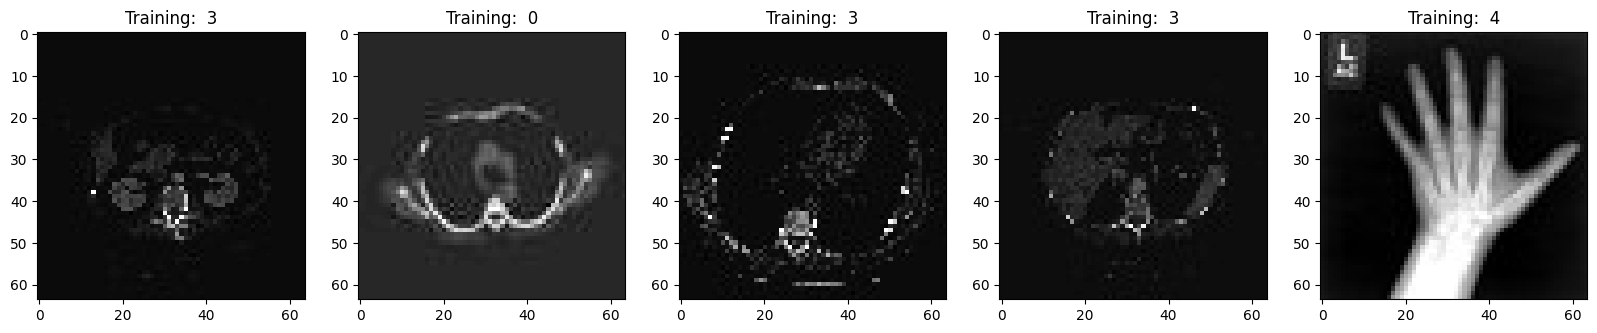

In [7]:
some_index = np.random.randint(0, len(train_loader.dataset), 10)
some_imgs = [train_loader.dataset.__getitem__(idx)[0] for idx in some_index]
some_labels = [train_loader.dataset.__getitem__(idx)[1] for idx in some_index]

show_examples(some_imgs[:5], some_labels[:5])

In [9]:
# get model
if args['model'] == 'logistic_regression':
    print('Using logistic regression')
    model = nn.Linear(args['img_size'], args['num_classes'])
elif args['model'] == 'MLP':
    print('MLP')
    model = MLP(dropout=0, hidden_1=512, hidden_2=512)

Using logistic regression


In [10]:
# Loss and optimizer
loss_function = nn.CrossEntropyLoss() # this combined the LogSoftmax and NLLLoss
optimizer = torch.optim.SGD(model.parameters(), lr=args['learning_rate'])

Lets build the trainer together

In [11]:
trainer = Trainer(args, train_loader, validation_loader, model, loss_function, optimizer)

Using device: cuda


Start the training!

In [12]:
trainer.overall_loop()

Epoch [1/50], Train Loss: 0.4475, Validation Loss: 0.3056
Epoch [2/50], Train Loss: 0.2382, Validation Loss: 0.2386
Epoch [3/50], Train Loss: 0.1940, Validation Loss: 0.2092
Epoch [4/50], Train Loss: 0.1709, Validation Loss: 0.1945
Epoch [5/50], Train Loss: 0.1558, Validation Loss: 0.1824
Epoch [6/50], Train Loss: 0.1450, Validation Loss: 0.1699
Epoch [7/50], Train Loss: 0.1368, Validation Loss: 0.1642
Epoch [8/50], Train Loss: 0.1301, Validation Loss: 0.1580
Epoch [9/50], Train Loss: 0.1248, Validation Loss: 0.1526
Epoch [10/50], Train Loss: 0.1202, Validation Loss: 0.1495
Epoch [11/50], Train Loss: 0.1163, Validation Loss: 0.1456
Epoch [12/50], Train Loss: 0.1128, Validation Loss: 0.1425
Epoch [13/50], Train Loss: 0.1097, Validation Loss: 0.1392
Epoch [14/50], Train Loss: 0.1070, Validation Loss: 0.1358
Epoch [15/50], Train Loss: 0.1046, Validation Loss: 0.1336
Epoch [16/50], Train Loss: 0.1024, Validation Loss: 0.1325
Epoch [17/50], Train Loss: 0.1003, Validation Loss: 0.1301
Epoch 

Calculating validation accuracy

In [13]:

correct = 0
total = 0
for images, labels in validation_loader:
    
    images = images.to(
        trainer.device,
        dtype=torch.float32
    )

    labels = labels.to(
        trainer.device,
        dtype=torch.long
    )
    
    images = images.reshape(-1, args['img_size'])
    outputs = model(images)

    _, predicted = torch.max(outputs.data, 1)
    total += labels.size(0)
    correct += (predicted == labels).sum().item()

print(correct)
print(total)

print('Accuracy of the model on the {} validation images: {:.2f} %'.format(total, 100 * correct / total))


16553
16954
Accuracy of the model on the 16954 validation images: 97.63 %


## Submit your homework

1. **Save** this notebook (Ctrl+S / Cmd+S) so all your code and outputs are in the file.
2. **Rename** the file to `hwA_<studentID>.ipynb`, e.g. `hwA_b12345678.ipynb`.
3. Run the cell below. It opens the submission page; **drag your renamed notebook** into it and enter your name.

You can submit more than once. The latest file counts.

In [ ]:
import webbrowser

SUBMIT_LINK = 'https://www.dropbox.com/request/zjfkwghdq0j1nxln58of'

print('Upload your saved and renamed notebook (hwA_<studentID>.ipynb) at:')
print(SUBMIT_LINK)
webbrowser.open(SUBMIT_LINK)